<a href="https://colab.research.google.com/github/juanmata23/gan-quickdraw/blob/main/GAN_QuickDraw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎨 GAN con Quick, Draw! — Explicando Generador, Discriminador y Funciones de Pérdida

**Idea:** una GAN (Red Generativa Antagónica) son **dos redes que compiten**:

| Red | Rol | Entrada | Salida |
|---|---|---|---|
| 🎭 **Generador (G)** | El *falsificador*: inventa dibujos | Ruido aleatorio `z` (100 números) | Imagen 28×28 falsa |
| 🕵️ **Discriminador (D)** | El *detective*: decide si es real o falso | Imagen 28×28 | Un número (real ↔ falso) |

- G intenta **engañar** a D. D intenta **no dejarse engañar**. Al competir, ambos mejoran.
- **Datos:** [Quick, Draw! Dataset](https://quickdraw.withgoogle.com/data) (dibujos de Google, 28×28 px).
- **Teoría:** [Curso de GAN de Google](https://developers.google.com/machine-learning/gan?hl=es-419)
- **Visualización interactiva:** [GAN Lab](https://poloclub.github.io/ganlab/)

**Pasos del cuaderno:** 1) Configuración → 2) Datos → 3) Crear Generador → 4) Crear Discriminador → 5) Funciones de pérdida → 6) Entrenamiento → 7) Gráficas de pérdidas → 8) Ver valores internos → 9) Resultado final.

## 1. Configuración
Aquí cambias la **categoría** y los hiperparámetros. Prueba `cat`, `apple`, `smiley face`, `house`, `star`, `fish`...

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import urllib.request, os, time

# ====== PARÁMETROS (puedes modificarlos) ======
CATEGORIA   = "cat"    # categoría de Quick, Draw! que la GAN aprenderá a dibujar
N_IMAGENES  = 8000    # cuántos dibujos reales usar
LATENT_DIM  = 100      # tamaño del vector de ruido z que recibe el Generador
BATCH_SIZE  = 128      # imágenes por paso de entrenamiento
EPOCAS      = 15       # vueltas completas al dataset
LR          = 2e-4     # tasa de aprendizaje (learning rate)
BETA_1      = 0.5      # parámetro de Adam recomendado para GANs

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Datos reales: Quick, Draw!
Descargamos los dibujos de la categoría elegida (formato `numpy_bitmap`, imágenes 28×28 en escala de grises).

Forma original: (8000, 784)


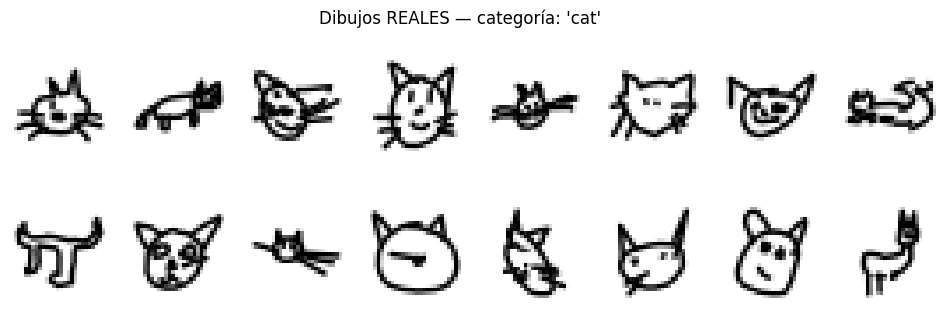

In [8]:
# Descargar el archivo .npy de la categoría desde el bucket público de Google
nombre_url = CATEGORIA.replace(" ", "%20")
url = f"https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{nombre_url}.npy"
archivo = f"{CATEGORIA.replace(' ', '_')}.npy"
if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

datos = np.load(archivo)[:N_IMAGENES]            # (N, 784)
print("Forma original:", datos.shape)

# Convertir a imágenes 28x28x1 y normalizar a [-1, 1]
# (el Generador termina con tanh, que produce valores en [-1, 1])
x_real = datos.reshape(-1, 28, 28, 1).astype("float32")
x_real = (x_real - 127.5) / 127.5

dataset = (tf.data.Dataset.from_tensor_slices(x_real)
           .shuffle(10000).batch(BATCH_SIZE, drop_remainder=True)
           .prefetch(tf.data.AUTOTUNE))

# Mostrar ejemplos reales
fig, axs = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axs.flat):
    ax.imshow(x_real[i, :, :, 0], cmap="gray_r"); ax.axis("off")
plt.suptitle(f"Dibujos REALES — categoría: '{CATEGORIA}'")
plt.show()

## 3. 🎭 Red neuronal GENERADORA (aquí se crea)
Recibe ruido `z` (100 números) y lo "agranda" con capas `Conv2DTranspose` hasta formar una imagen 28×28.

- `Dense`: convierte el ruido en muchos números (7·7·256).
- `Reshape`: los acomoda como imagen pequeña 7×7 con 256 canales.
- `Conv2DTranspose`: *deconvolución*, aumenta el tamaño (7→14→28).
- `BatchNormalization`: estabiliza el entrenamiento.
- `LeakyReLU`: activación que deja pasar un poco de señal negativa.
- `tanh`: salida entre -1 y 1 (igual que los datos normalizados).

In [9]:
def crear_generador():
    """★ AQUÍ SE CREA LA RED GENERADORA ★
    Entrada : vector de ruido de tamaño LATENT_DIM
    Salida  : imagen falsa de 28x28x1
    """
    modelo = models.Sequential(name="Generador")
    modelo.add(layers.Input(shape=(LATENT_DIM,)))                       # entrada: ruido z

    modelo.add(layers.Dense(7 * 7 * 256, use_bias=False))               # expande el ruido
    modelo.add(layers.BatchNormalization())                             # normaliza
    modelo.add(layers.LeakyReLU(0.2))                                   # activación
    modelo.add(layers.Reshape((7, 7, 256)))                             # lo vuelve "imagen" 7x7

    modelo.add(layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False))  # 7x7
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.LeakyReLU(0.2))

    modelo.add(layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False))   # 14x14
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.LeakyReLU(0.2))

    modelo.add(layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh")) # 28x28x1
    return modelo

generador = crear_generador()
generador.summary()   # tabla con capas, formas y número de parámetros

Model: "Generador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

## 4. 🕵️ Red neuronal DISCRIMINADORA (aquí se crea)
Es un clasificador (CNN) que recibe una imagen 28×28 y devuelve **un solo número** (*logit*):
- valor **alto** → "creo que es REAL"
- valor **bajo/negativo** → "creo que es FALSA"

- `Conv2D` con `strides=2`: reduce la imagen (28→14→7) extrayendo rasgos.
- `Dropout`: apaga neuronas al azar para que D no se vuelva "demasiado fuerte".
- `Dense(1)`: la decisión final (sin sigmoide; la pérdida la aplica internamente).

In [10]:
def crear_discriminador():
    """★ AQUÍ SE CREA LA RED DISCRIMINADORA ★
    Entrada : imagen 28x28x1 (real o falsa)
    Salida  : 1 número (logit): >0 parece real, <0 parece falsa
    """
    modelo = models.Sequential(name="Discriminador")
    modelo.add(layers.Input(shape=(28, 28, 1)))                          # entrada: imagen

    modelo.add(layers.Conv2D(64, 5, strides=2, padding="same"))          # 28x28 -> 14x14
    modelo.add(layers.LeakyReLU(0.2))
    modelo.add(layers.Dropout(0.3))

    modelo.add(layers.Conv2D(128, 5, strides=2, padding="same"))         # 14x14 -> 7x7
    modelo.add(layers.LeakyReLU(0.2))
    modelo.add(layers.Dropout(0.3))

    modelo.add(layers.Flatten())                                         # aplana
    modelo.add(layers.Dense(1))                                          # decisión real/falso
    return modelo

discriminador = crear_discriminador()
discriminador.summary()

Model: "Discriminador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## 5. 📉 Funciones de pérdida (loss)
Usamos **Binary Cross-Entropy (BCE)**: mide qué tan equivocada está una predicción respecto a la etiqueta (1 = real, 0 = falsa).

- **Pérdida del Discriminador:** `loss_D = BCE(reales, 1) + BCE(falsas, 0)` → quiere decir "reales=real, falsas=falsas".
- **Pérdida del Generador:** `loss_G = BCE(falsas, 1)` → quiere que D diga que sus falsas son reales.

📌 Lectura rápida: **si G mejora, loss_G baja y loss_D sube** (y viceversa). En equilibrio, D ≈ 50% de acierto y `loss_D ≈ 1.386` (= 2·ln 2).

In [11]:
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)  # D devuelve logits, no probabilidades

def perdida_discriminador(salida_real, salida_falsa):
    """D quiere: imágenes reales -> 1  e  imágenes falsas -> 0"""
    loss_real  = bce(tf.ones_like(salida_real),  salida_real)    # etiqueta 1 para reales
    loss_falsa = bce(tf.zeros_like(salida_falsa), salida_falsa)  # etiqueta 0 para falsas
    return loss_real + loss_falsa

def perdida_generador(salida_falsa):
    """G quiere engañar a D: que sus imágenes falsas se clasifiquen como 1 (reales)"""
    return bce(tf.ones_like(salida_falsa), salida_falsa)

# Cada red tiene su propio optimizador (Adam)
opt_generador     = tf.keras.optimizers.Adam(LR, beta_1=BETA_1)
opt_discriminador = tf.keras.optimizers.Adam(LR, beta_1=BETA_1)

## 6. Entrenamiento
En **cada paso**:
1. Se genera ruido `z` → G crea imágenes falsas.
2. D mira un lote de reales y uno de falsas.
3. Se calculan `loss_G` y `loss_D`.
4. Se actualizan **los pesos de ambas redes** con los gradientes (cada una intenta bajar su propia pérdida).

También guardamos `D(real)` y `D(falsa)`: la probabilidad promedio que D asigna a "es real".

Época 01/15 | loss_G=0.591 | loss_D=1.298 | D(real)=0.62 | D(falsa)=0.56 | 10.3s


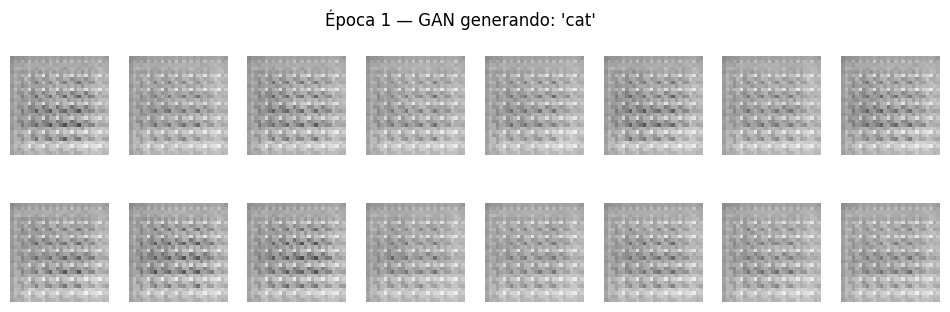

Época 02/15 | loss_G=0.676 | loss_D=1.272 | D(real)=0.58 | D(falsa)=0.51 | 1.8s
Época 03/15 | loss_G=0.705 | loss_D=1.295 | D(real)=0.55 | D(falsa)=0.50 | 1.8s
Época 04/15 | loss_G=0.726 | loss_D=1.297 | D(real)=0.54 | D(falsa)=0.49 | 1.8s
Época 05/15 | loss_G=0.797 | loss_D=1.237 | D(real)=0.55 | D(falsa)=0.46 | 2.5s


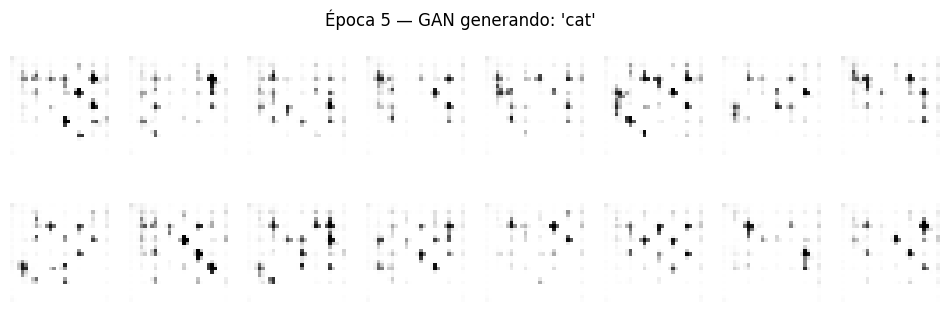

Época 06/15 | loss_G=0.883 | loss_D=1.142 | D(real)=0.60 | D(falsa)=0.43 | 1.8s
Época 07/15 | loss_G=0.874 | loss_D=1.222 | D(real)=0.55 | D(falsa)=0.43 | 1.8s
Época 08/15 | loss_G=0.917 | loss_D=1.155 | D(real)=0.59 | D(falsa)=0.42 | 1.8s
Época 09/15 | loss_G=0.927 | loss_D=1.174 | D(real)=0.58 | D(falsa)=0.42 | 1.8s
Época 10/15 | loss_G=0.919 | loss_D=1.174 | D(real)=0.58 | D(falsa)=0.42 | 1.8s


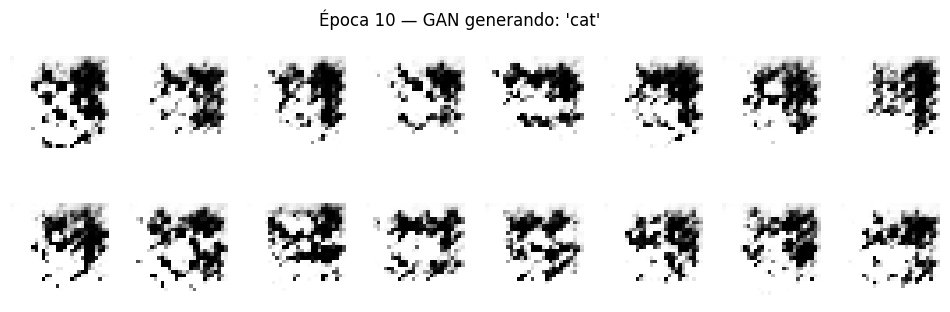

Época 11/15 | loss_G=0.897 | loss_D=1.182 | D(real)=0.58 | D(falsa)=0.43 | 1.8s
Época 12/15 | loss_G=0.884 | loss_D=1.209 | D(real)=0.57 | D(falsa)=0.43 | 1.9s
Época 13/15 | loss_G=0.884 | loss_D=1.219 | D(real)=0.56 | D(falsa)=0.43 | 1.8s
Época 14/15 | loss_G=0.992 | loss_D=1.129 | D(real)=0.59 | D(falsa)=0.40 | 1.8s
Época 15/15 | loss_G=0.911 | loss_D=1.207 | D(real)=0.58 | D(falsa)=0.43 | 1.8s


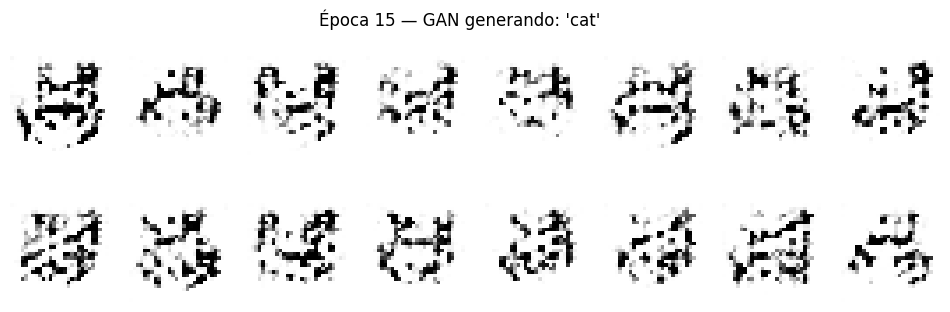

In [12]:
@tf.function  # compila el paso para que corra más rápido
def paso_entrenamiento(imagenes_reales):
    ruido = tf.random.normal([BATCH_SIZE, LATENT_DIM])            # z aleatorio

    with tf.GradientTape() as cinta_g, tf.GradientTape() as cinta_d:
        imagenes_falsas = generador(ruido, training=True)          # G crea falsas
        salida_real  = discriminador(imagenes_reales, training=True)   # D evalúa reales
        salida_falsa = discriminador(imagenes_falsas, training=True)   # D evalúa falsas

        loss_g = perdida_generador(salida_falsa)
        loss_d = perdida_discriminador(salida_real, salida_falsa)

    # Gradientes: cuánto cambiar cada peso para reducir la pérdida
    grad_g = cinta_g.gradient(loss_g, generador.trainable_variables)
    grad_d = cinta_d.gradient(loss_d, discriminador.trainable_variables)

    # Actualizar los pesos de cada red
    opt_generador.apply_gradients(zip(grad_g, generador.trainable_variables))
    opt_discriminador.apply_gradients(zip(grad_d, discriminador.trainable_variables))

    d_real  = tf.reduce_mean(tf.sigmoid(salida_real))    # prob. media que D da a reales
    d_falsa = tf.reduce_mean(tf.sigmoid(salida_falsa))   # prob. media que D da a falsas
    return loss_g, loss_d, d_real, d_falsa

# Ruido FIJO para ver cómo evoluciona el mismo "dibujo" época tras época
ruido_fijo = tf.random.normal([16, LATENT_DIM])

def mostrar_muestras(epoca):
    imgs = generador(ruido_fijo, training=False).numpy()
    fig, axs = plt.subplots(2, 8, figsize=(12, 3.5))
    for i, ax in enumerate(axs.flat):
        ax.imshow(imgs[i, :, :, 0], cmap="gray_r", vmin=-1, vmax=1); ax.axis("off")
    plt.suptitle(f"Época {epoca} — GAN generando: '{CATEGORIA}'")
    plt.show()

historial = {"loss_g": [], "loss_d": [], "d_real": [], "d_falsa": []}

for epoca in range(1, EPOCAS + 1):
    t0 = time.time()
    acum = np.zeros(4); n = 0
    for lote in dataset:
        resultados = paso_entrenamiento(lote)
        acum += np.array([r.numpy() for r in resultados]); n += 1
    acum /= n
    for k, v in zip(historial.keys(), acum):
        historial[k].append(v)

    print(f"Época {epoca:02d}/{EPOCAS} | loss_G={acum[0]:.3f} | loss_D={acum[1]:.3f} | "
          f"D(real)={acum[2]:.2f} | D(falsa)={acum[3]:.2f} | {time.time()-t0:.1f}s")
    if epoca == 1 or epoca % 5 == 0:
        mostrar_muestras(epoca)

## 7. 📉 Ver las funciones de pérdida
Si todo va bien, las curvas **no** bajan a cero: se mantienen peleando entre sí (eso es normal en una GAN).

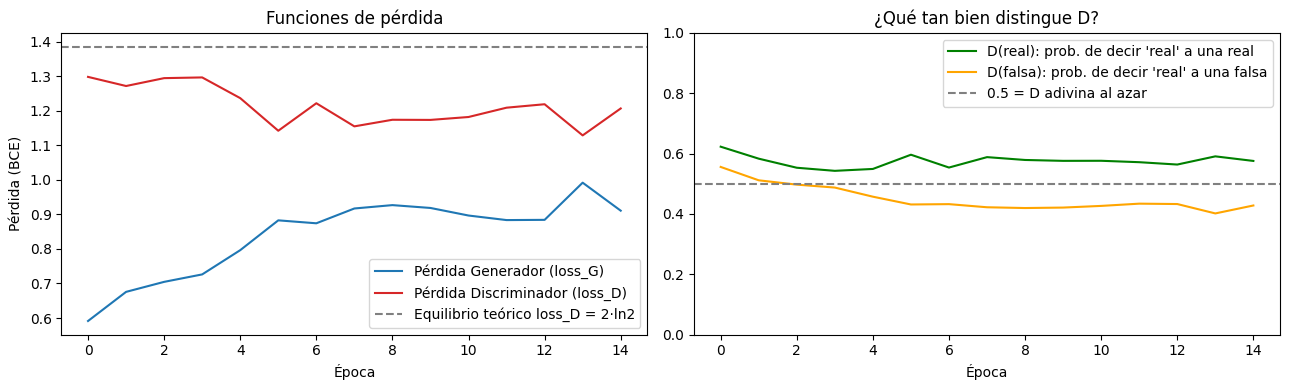

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Pérdidas
axs[0].plot(historial["loss_g"], label="Pérdida Generador (loss_G)", color="tab:blue")
axs[0].plot(historial["loss_d"], label="Pérdida Discriminador (loss_D)", color="tab:red")
axs[0].axhline(1.386, ls="--", color="gray", label="Equilibrio teórico loss_D = 2·ln2")
axs[0].set_title("Funciones de pérdida"); axs[0].set_xlabel("Época"); axs[0].set_ylabel("Pérdida (BCE)")
axs[0].legend()

# Qué tan seguro está D
axs[1].plot(historial["d_real"],  label="D(real): prob. de decir 'real' a una real", color="green")
axs[1].plot(historial["d_falsa"], label="D(falsa): prob. de decir 'real' a una falsa", color="orange")
axs[1].axhline(0.5, ls="--", color="gray", label="0.5 = D adivina al azar")
axs[1].set_title("¿Qué tan bien distingue D?"); axs[1].set_xlabel("Época"); axs[1].set_ylim(0, 1)
axs[1].legend()
plt.tight_layout(); plt.show()

## 8. 🔍 Ver los valores (parámetros) del Generador y del Discriminador
Cada capa tiene **pesos** (kernel) y **sesgos** (bias) que se aprendieron durante el entrenamiento.

🎭 GENERADOR — parámetros por capa


,capa,parámetro,forma,cantidad,media,desv.est,mín,máx
0,dense_2,kernel,"(100, 12544)",1254400,0.0000,0.0154,-0.063,0.063
1,batch_normalization_3,gamma,"(12544,)",12544,1.0001,0.0334,0.892,1.114
2,batch_normalization_3,beta,"(12544,)",12544,-0.0014,0.0350,-0.115,0.115
3,batch_normalization_3,moving_mean,"(12544,)",12544,-0.0000,0.0010,-0.004,0.004
4,batch_normalization_3,moving_variance,"(12544,)",12544,0.0227,0.0020,0.015,0.029
5,conv2d_transpose_3,kernel,"(5, 5, 128, 256)",819200,-0.0017,0.0180,-0.085,0.080
6,batch_normalization_4,gamma,"(128,)",128,1.0029,0.0143,0.969,1.033
7,batch_normalization_4,beta,"(128,)",128,-0.0253,0.0165,-0.062,0.021
8,batch_normalization_4,moving_mean,"(128,)",128,-2.4077,2.2655,-7.983,3.481
9,batch_normalization_4,moving_variance,"(128,)",128,9.0834,1.9660,6.459,16.496


Total parámetros Generador: 2,330,945

🕵️ DISCRIMINADOR — parámetros por capa


,capa,parámetro,forma,cantidad,media,desv.est,mín,máx
0,conv2d_2,kernel,"(5, 5, 1, 64)",1600,0.0001,0.0388,-0.105,0.101
1,conv2d_2,bias,"(64,)",64,-0.0107,0.0332,-0.067,0.063
2,conv2d_3,kernel,"(5, 5, 64, 128)",204800,-0.0006,0.0243,-0.105,0.091
3,conv2d_3,bias,"(128,)",128,0.0008,0.0263,-0.048,0.046
4,dense_3,kernel,"(6272, 1)",6272,-0.0009,0.0265,-0.086,0.081
5,dense_3,bias,"(1,)",1,-0.0269,0.0000,-0.027,-0.027


Total parámetros Discriminador: 212,865


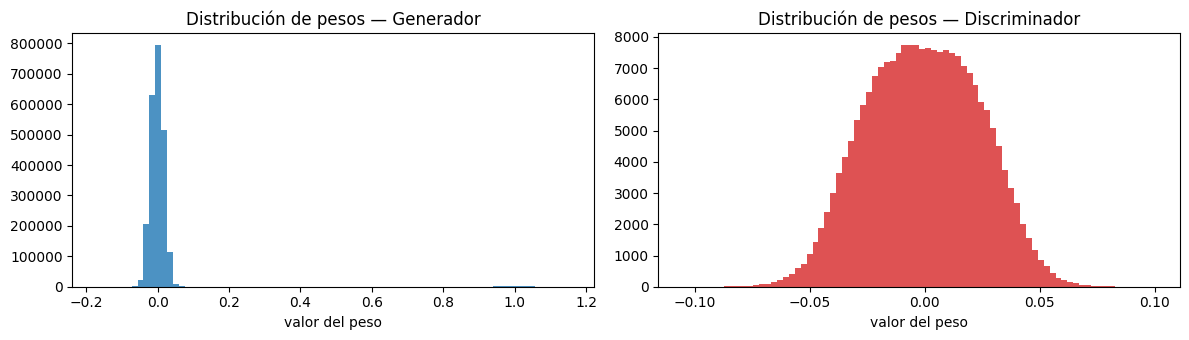

In [14]:
def tabla_parametros(modelo):
    """Devuelve una tabla con los parámetros de cada capa de una red"""
    filas = []
    for capa in modelo.layers:
        for w in capa.weights:
            v = w.numpy()
            filas.append({
                "capa": capa.name, "parámetro": w.name.split("/")[-1],
                "forma": str(v.shape), "cantidad": v.size,
                "media": round(float(v.mean()), 4), "desv.est": round(float(v.std()), 4),
                "mín": round(float(v.min()), 3), "máx": round(float(v.max()), 3),
            })
    return pd.DataFrame(filas)

print("🎭 GENERADOR — parámetros por capa")
display(tabla_parametros(generador))
print(f"Total parámetros Generador: {generador.count_params():,}\n")

print("🕵️ DISCRIMINADOR — parámetros por capa")
display(tabla_parametros(discriminador))
print(f"Total parámetros Discriminador: {discriminador.count_params():,}")

# Histograma de todos los pesos de cada red
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, modelo, nombre, color in [(axs[0], generador, "Generador", "tab:blue"),
                                  (axs[1], discriminador, "Discriminador", "tab:red")]:
    todos = np.concatenate([w.numpy().ravel() for w in modelo.trainable_weights])
    ax.hist(todos, bins=80, color=color, alpha=0.8)
    ax.set_title(f"Distribución de pesos — {nombre}"); ax.set_xlabel("valor del peso")
plt.tight_layout(); plt.show()

Vector de ruido z (primeros 10 de 100 valores):
[-0.69  -0.445 -2.836  0.798 -0.903 -0.008  0.074 -1.388  0.389 -0.785]

D(imagen REAL)  -> logit=+0.327  | prob. 'real' = 58.1%
D(imagen FALSA) -> logit=-0.285  | prob. 'real' = 42.9%


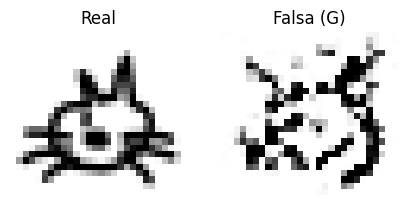

In [15]:
# ---- Un ejemplo concreto de principio a fin ----
z = tf.random.normal([1, LATENT_DIM])
img_falsa = generador(z, training=False)

print("Vector de ruido z (primeros 10 de 100 valores):")
print(np.round(z.numpy()[0][:10], 3))

logit_falsa = discriminador(img_falsa, training=False).numpy()[0][0]
logit_real  = discriminador(x_real[:1], training=False).numpy()[0][0]
sigmoide = lambda x: 1 / (1 + np.exp(-x))

print(f"\nD(imagen REAL)  -> logit={logit_real:+.3f}  | prob. 'real' = {sigmoide(logit_real):.1%}")
print(f"D(imagen FALSA) -> logit={logit_falsa:+.3f}  | prob. 'real' = {sigmoide(logit_falsa):.1%}")

fig, axs = plt.subplots(1, 2, figsize=(5, 2.8))
axs[0].imshow(x_real[0, :, :, 0], cmap="gray_r"); axs[0].set_title("Real"); axs[0].axis("off")
axs[1].imshow(img_falsa[0, :, :, 0], cmap="gray_r"); axs[1].set_title("Falsa (G)"); axs[1].axis("off")
plt.show()

## 9. 🖼️ Resultado final de la GAN
Imágenes **nuevas**, inventadas por el Generador a partir de ruido aleatorio.

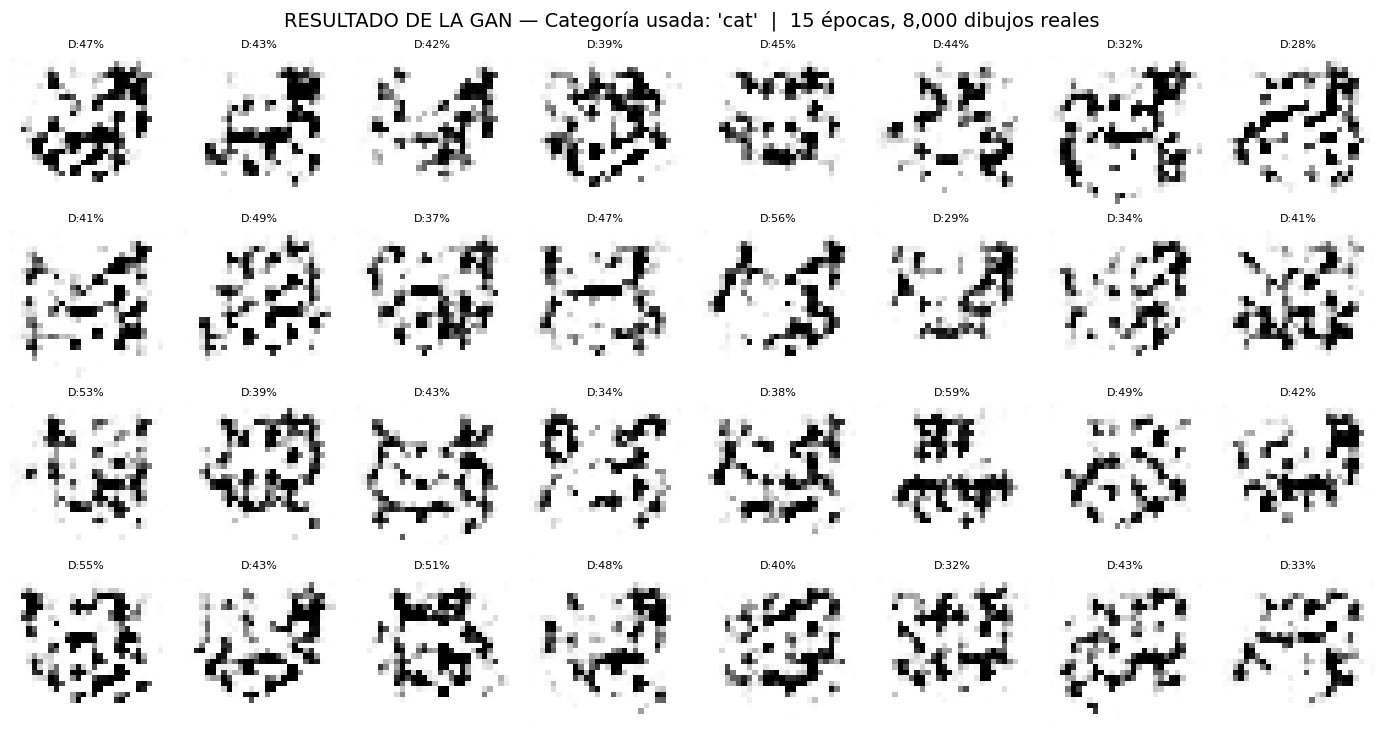

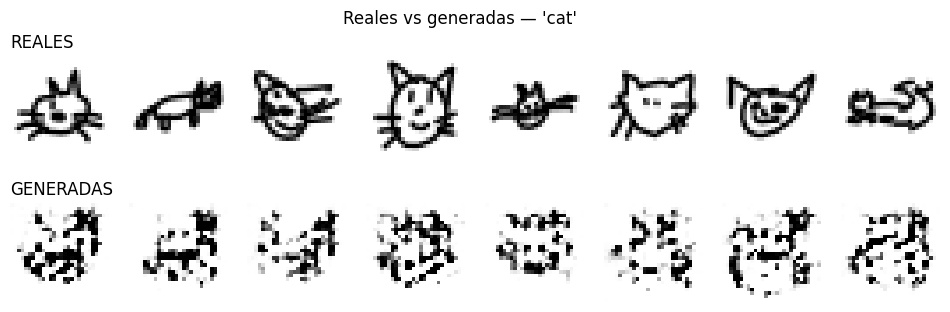

In [16]:
ruido_nuevo = tf.random.normal([32, LATENT_DIM])
imgs = generador(ruido_nuevo, training=False).numpy()
puntaje = tf.sigmoid(discriminador(imgs, training=False)).numpy().ravel()  # qué tan "reales" le parecen a D

fig, axs = plt.subplots(4, 8, figsize=(14, 7.5))
for i, ax in enumerate(axs.flat):
    ax.imshow(imgs[i, :, :, 0], cmap="gray_r", vmin=-1, vmax=1)
    ax.set_title(f"D:{puntaje[i]:.0%}", fontsize=8); ax.axis("off")
plt.suptitle(f"RESULTADO DE LA GAN — Categoría usada: '{CATEGORIA}'  |  "
             f"{EPOCAS} épocas, {N_IMAGENES:,} dibujos reales", fontsize=14)
plt.tight_layout(); plt.show()

# Comparación lado a lado
fig, axs = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axs[0, i].imshow(x_real[i, :, :, 0], cmap="gray_r"); axs[0, i].axis("off")
    axs[1, i].imshow(imgs[i, :, :, 0], cmap="gray_r", vmin=-1, vmax=1); axs[1, i].axis("off")
axs[0, 0].set_title("REALES", loc="left"); axs[1, 0].set_title("GENERADAS", loc="left")
plt.suptitle(f"Reales vs generadas — '{CATEGORIA}'"); plt.show()

## 🎓 Conclusiones (para tu informe)
- **Generador:** ___ parámetros; transforma ruido de 100 valores en una imagen 28×28.
- **Discriminador:** ___ parámetros; CNN que clasifica real vs falsa.
- **Pérdidas:** BCE para ambas; el equilibrio ideal es loss_D ≈ 1.386 y D(real) ≈ D(falsa) ≈ 0.5.
- **Categoría usada:** ___ .
- **Experimento extra:** cambia `CATEGORIA` y compara resultados; o cambia `EPOCAS` (10 vs 50) y observa la calidad.